original image:


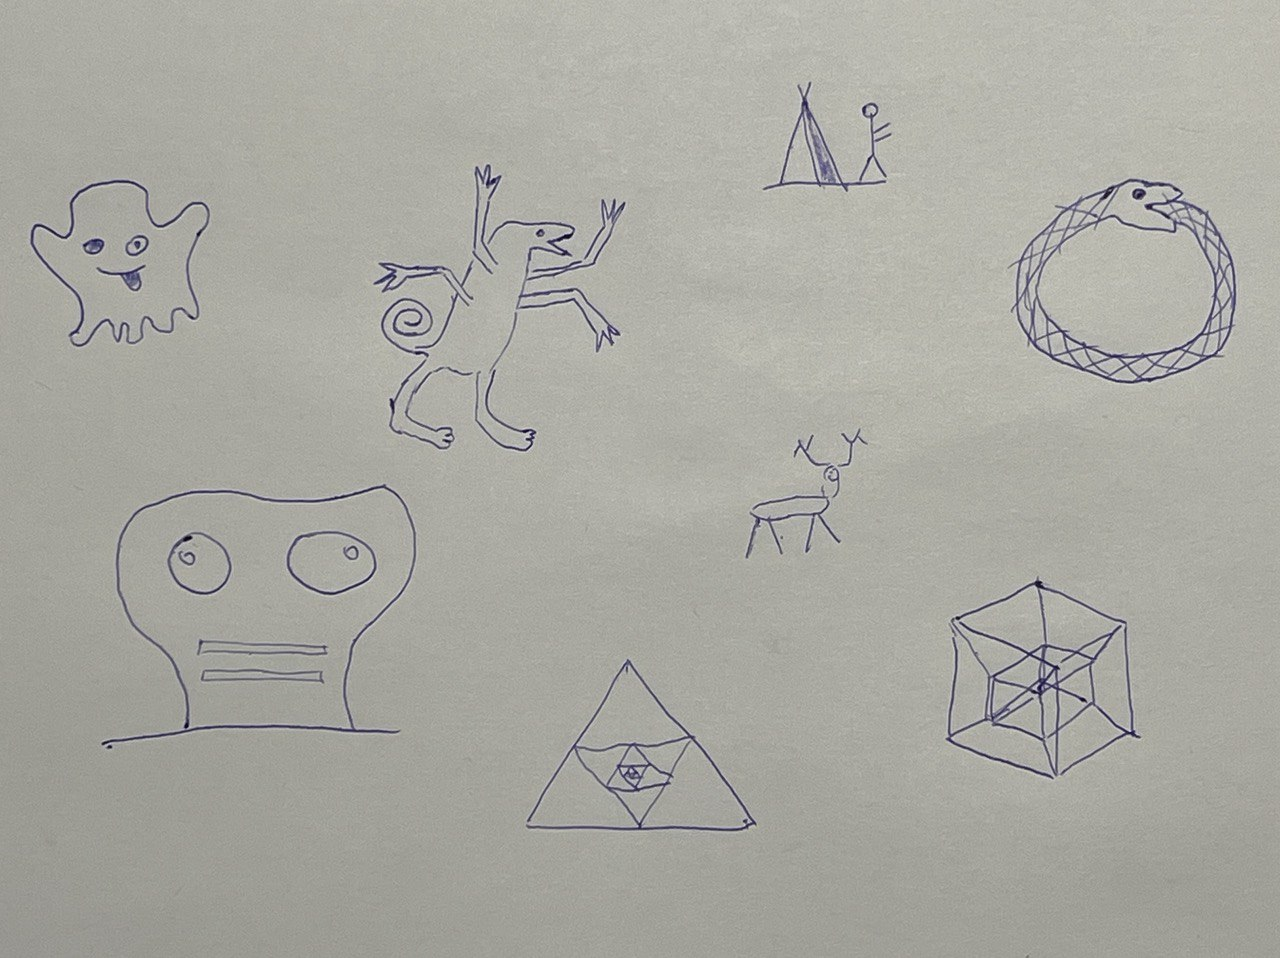

7.7676777839660645 seconds to shrink 50 pixels by PySeamCarver
0.340548038482666 seconds to shrink 50 pixels by CySeamCarver
0.18978571891784668 seconds to shrink 50 pixels by CppSeamCarver
0.32976698875427246 seconds to shrink 50 pixels by CtypesSeamCarver
0.31574201583862305 seconds to shrink 50 pixels by CSeamCarver
1.6660563945770264 seconds to shrink 600 pixels by CppSeamCarver
shrunk image by CppSeamCarver:


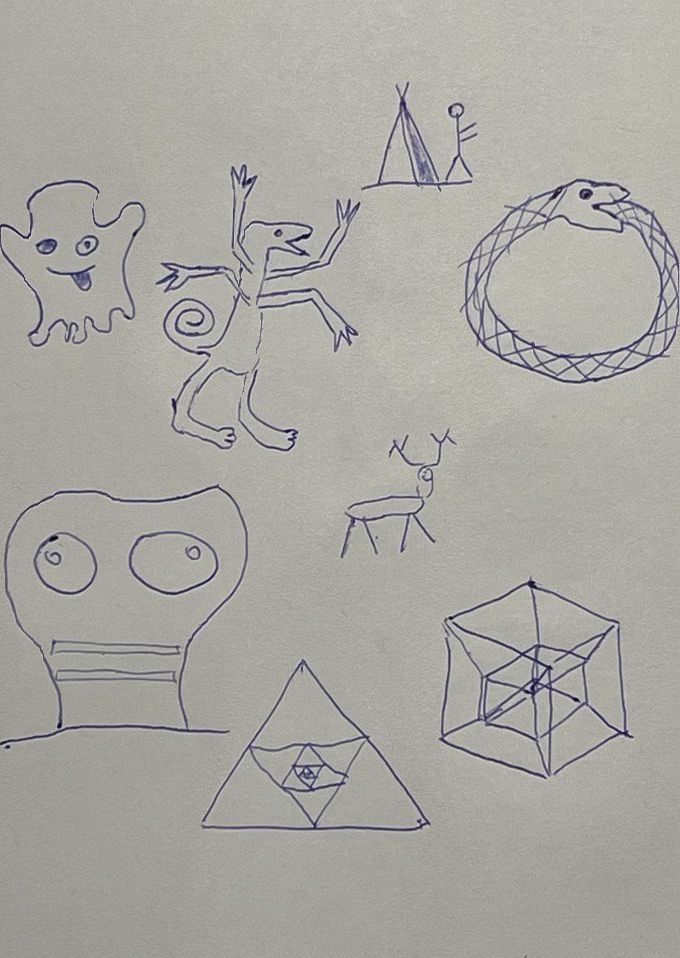

In [1]:
from PIL import Image
import time

from py_seam_carver.py_seam_carver import PySeamCarver
from cy_seam_carver.seam_carver import CySeamCarver
from cpp_seam_carver.cpp_seam_carver import CppSeamCarver
from ctypes_seam_carver.ctypes_seam_carver import CtypesSeamCarver
from c_seam_carver.c_seam_carver import CSeamCarver

image = Image.open('tundra_1280x958.jpeg')
print('original image:')
display(image)

def shrink_horizontally(sc, description, pixels_to_shrink, show=False):
    start_time = time.time()
    incremental_cost_updates = True
    sc.shrink_horizontally(pixels_to_shrink, incremental_cost_updates)
    finish_time = time.time()
    print(f"{finish_time - start_time} seconds to shrink {pixels_to_shrink} pixels by {description}")
    shrunk_image = sc.get_shrunk_image()
    
    shrunk_image.save(f'tundra_resized_{1230-pixels_to_shrink}x958.png', optimize=True)
    if show:
        print(f'shrunk image by {description}:')
        display(shrunk_image)

pixels_to_shrink = 50

shrink_horizontally(sc=PySeamCarver(image), description='PySeamCarver', pixels_to_shrink=pixels_to_shrink)
shrink_horizontally(sc=CySeamCarver(image), description='CySeamCarver', pixels_to_shrink=pixels_to_shrink)
shrink_horizontally(sc=CppSeamCarver(image), description='CppSeamCarver', pixels_to_shrink=pixels_to_shrink)
shrink_horizontally(sc=CtypesSeamCarver(image), description='CtypesSeamCarver', pixels_to_shrink=pixels_to_shrink)
shrink_horizontally(sc=CSeamCarver(image), description='CSeamCarver', pixels_to_shrink=pixels_to_shrink)

shrink_horizontally(sc=CppSeamCarver(image), description='CppSeamCarver', pixels_to_shrink=600, show=True)


['__class__', '__delattr__', '__delitem__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setitem__', '__sizeof__', '__str__', '__subclasshook__']
width: 1280, height: 958
1. Slow approach via conversion to tuple of tuples


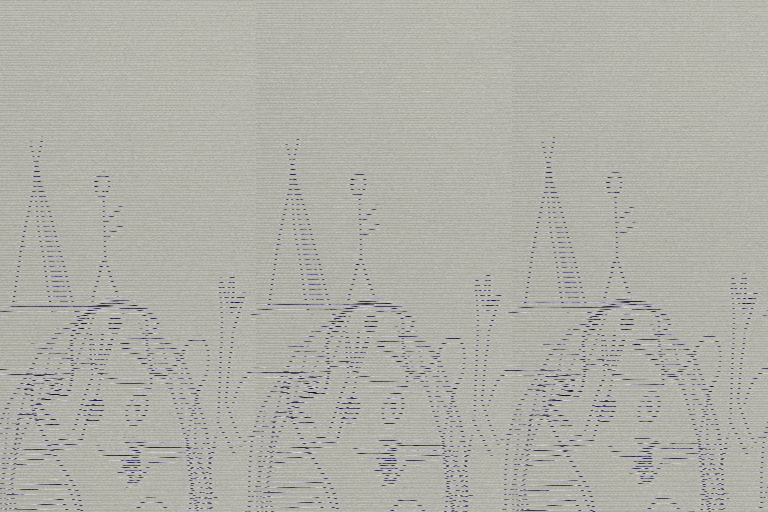

2. Faster conversion via numpy


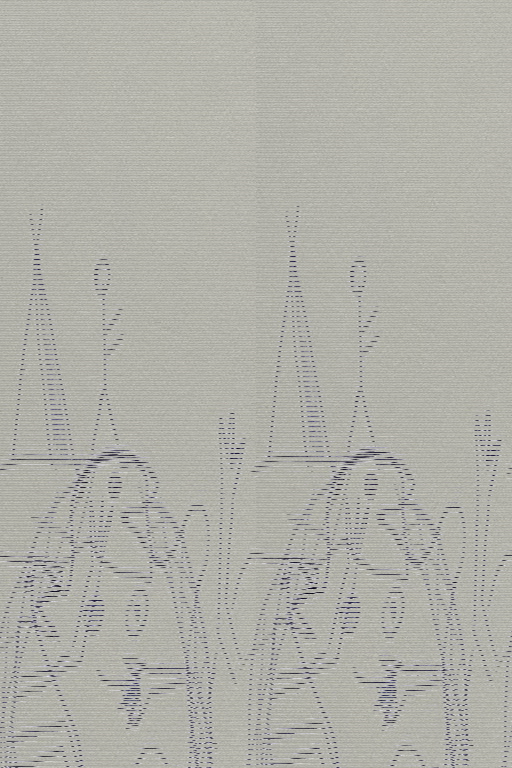

In [2]:
import numpy as np
from PIL import Image
from IPython.display import display

image = Image.open('tundra_1280x958.jpeg')
pixels = image.load()
print(pixels)
print(dir(pixels))

width, height = image.size
print(f'width: {width}, height: {height}')

print('1. Slow approach via conversion to tuple of tuples')
data = image.get_flattened_data()
#print(data)
#print(f'len(data): {len(data)} vs w*h: {width * height}')
# tuple of tuples?
#print(data[:128])
#print(dir(data))
#print(type(data))
data_as_np_array = np.array(data[:768 * 512])
#print('data_as_np_array:')
#print(data_as_np_array)
#print(f'data_as_np_array size:{len(data_as_np_array)}')
output_array1_flat = data_as_np_array.flatten()
output_array1_flat = np.uint8(output_array1_flat) #
output_array1_2d = np.reshape(output_array1_flat[:3*512*768], (512, 768, 3))
#print('output_array1_flat:')
#print(output_array1_flat)
#print('output_array1_2d:')
#print(output_array1_2d)
output_image1 = Image.fromarray(output_array1_2d)
display(output_image1)


print('2. Faster conversion via numpy')
input_array = np.asarray(image)
#print('input_array:')
#print(input_array)
flat_input_array = input_array.flatten()
#print(flat_input_array[:128])
output_array = np.reshape(flat_input_array[:3*512*768], (768, 512, 3))
#output_image = Image.fromarray(np.uint8(output_array))
output_image = Image.fromarray(output_array)
display(output_image)



Seconds per run (construct + shrink + export)
             class      1 seam    50 seams   600 seams
      PySeamCarver       3.716       9.924      81.267
      CySeamCarver       0.558       0.678       4.490
     CppSeamCarver       0.085       0.225       2.029
       CSeamCarver       0.082       0.217       1.987
  CtypesSeamCarver       0.082       0.215       2.012

Breakdown at 600 seams: construct / shrink / export seconds
      PySeamCarver  1.849 / 79.332 / 0.086
      CySeamCarver  0.331 / 4.094 / 0.064
     CppSeamCarver  0.040 / 1.979 / 0.009
       CSeamCarver  0.040 / 1.937 / 0.010
  CtypesSeamCarver  0.053 / 1.949 / 0.011

Speedup over PySeamCarver at 1 seam: CySeamCarver x6.7, CppSeamCarver x43.7, CSeamCarver x45.5, CtypesSeamCarver x45.2

Speedup over PySeamCarver at 50 seams: CySeamCarver x14.6, CppSeamCarver x44.1, CSeamCarver x45.6, CtypesSeamCarver x46.1

Speedup over PySeamCarver at 600 seams: CySeamCarver x18.1, CppSeamCarver x40.1, CSeamCarver x40.9, CtypesSe

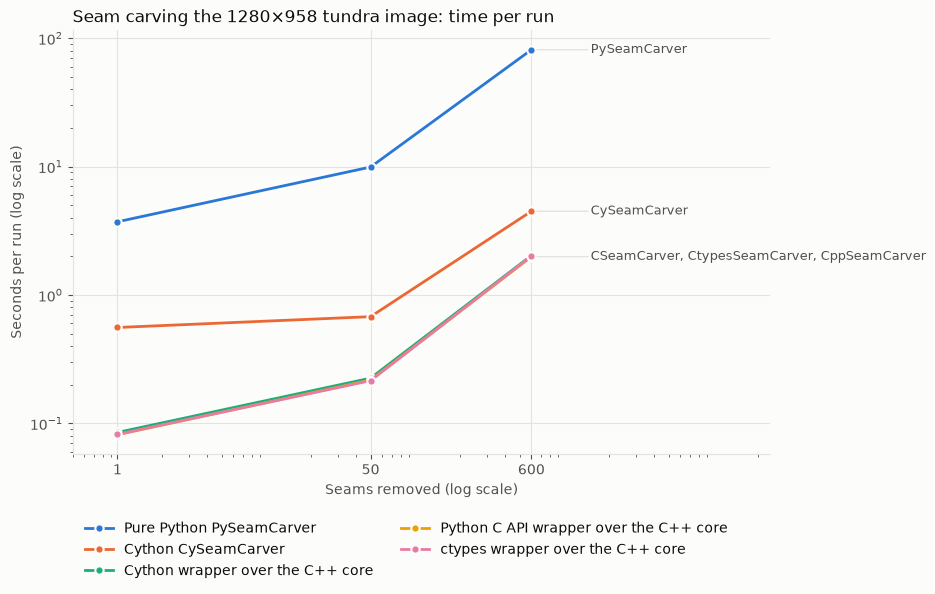

In [3]:
# Time per run (construct + shrink + export) of every seam carver class for growing numbers of removed seams:
# a table in the console, then a log-log plot. Takes about a minute and a half, mostly PySeamCarver.
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from py_seam_carver.py_seam_carver import PySeamCarver
from cy_seam_carver.seam_carver import CySeamCarver
from cpp_seam_carver.cpp_seam_carver import CppSeamCarver
from c_seam_carver.c_seam_carver import CSeamCarver
from ctypes_seam_carver.ctypes_seam_carver import CtypesSeamCarver

carvers = [  # (legend label, short label, class); colors follow this order
    ('Pure Python PySeamCarver', 'PySeamCarver', PySeamCarver),
    ('Cython CySeamCarver', 'CySeamCarver', CySeamCarver),
    ('Cython wrapper over the C++ core', 'CppSeamCarver', CppSeamCarver),
    ('Python C API wrapper over the C++ core', 'CSeamCarver', CSeamCarver),
    ('ctypes wrapper over the C++ core', 'CtypesSeamCarver', CtypesSeamCarver),
]
seam_counts = [1, 50, 600]
image = Image.open('tundra_1280x958.jpeg')

def seams_text(seams):
    return f'{seams} seam' if seams == 1 else f'{seams} seams'

seconds_per_run = {short: [] for _, short, _ in carvers}
phases = {}  # (short label, seams) -> (construct, shrink, export) seconds
for seams in seam_counts:
    reference = None
    for label, short, carver_class in carvers:
        start = time.perf_counter()
        carver = carver_class(image)
        constructed = time.perf_counter()
        carver.shrink_horizontally(seams)
        shrunk = time.perf_counter()
        pixels = np.asarray(carver.get_shrunk_image())
        exported = time.perf_counter()
        del carver
        # Every class must remove exactly the same seams
        reference = pixels if reference is None else reference
        assert np.array_equal(pixels, reference), f'{short} differs from {carvers[0][1]} after {seams_text(seams)}'
        phases[short, seams] = (constructed - start, shrunk - constructed, exported - shrunk)
        seconds_per_run[short].append(exported - start)

print('Seconds per run (construct + shrink + export)')
print(f'{"class":>18s}' + ''.join(f'{seams_text(seams):>12s}' for seams in seam_counts))
for _, short, _ in carvers:
    print(f'{short:>18s}' + ''.join(f'{t:12.3f}' for t in seconds_per_run[short]))

print(f'\nBreakdown at {seams_text(seam_counts[-1])}: construct / shrink / export seconds')
for _, short, _ in carvers:
    print(f'{short:>18s}  ' + ' / '.join(f'{t:.3f}' for t in phases[short, seam_counts[-1]]))

for i, seams in enumerate(seam_counts):
    python_time = seconds_per_run['PySeamCarver'][i]
    print(f'\nSpeedup over PySeamCarver at {seams_text(seams)}: '
          + ', '.join(f'{short} x{python_time / seconds_per_run[short][i]:.1f}' for _, short, _ in carvers[1:]))

# Categorical slots 1-5 of the reference palette, validated for adjacent lines on a light surface
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
surface, text_primary, text_secondary, grid = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'

fig, ax = plt.subplots(figsize=(9, 5.5), facecolor=surface)
ax.set_facecolor(surface)
for (label, short, _), color in zip(carvers, colors):
    ax.plot(seam_counts, seconds_per_run[short], color=color, linewidth=2, marker='o', markersize=6,
            markeredgecolor=surface, markeredgewidth=1.5, label=label)

# Direct labels at the line ends: lines ending within 15% of each other (the three wrappers
# over the same C++ core) share one label, the others are nudged apart where they end close together
groups = []  # [end value, short labels]
for value, short in sorted((seconds_per_run[short][-1], short) for _, short, _ in carvers):
    if groups and value / groups[-1][0] < 1.15:
        groups[-1][1].append(short)
    else:
        groups.append([value, [short]])
label_y = []
for value, shorts in groups:
    y = max(value, label_y[-1] * 1.8) if label_y else value
    label_y.append(y)
    ax.annotate(', '.join(shorts), xy=(seam_counts[-1], value), xytext=(seam_counts[-1] * 2.5, y),
                color=text_secondary, fontsize=9, va='center',
                arrowprops=dict(arrowstyle='-', color=grid, linewidth=1, shrinkA=0, shrinkB=4))

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(seam_counts[0] / 2, seam_counts[-1] * 40)
ax.set_xticks(seam_counts, [str(seams) for seams in seam_counts])  # only the measured seam counts
ax.set_xlabel('Seams removed (log scale)', color=text_secondary)
ax.set_ylabel('Seconds per run (log scale)', color=text_secondary)
ax.set_title('Seam carving the 1280×958 tundra image: time per run', color=text_primary, loc='left')
ax.grid(True, which='major', color=grid, linewidth=0.8)
ax.tick_params(colors=text_secondary, which='both')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
for side in ('left', 'bottom'):
    ax.spines[side].set_color(grid)
# Below the plot: the lines leave no free corner inside it
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.13), ncol=2, frameon=False, labelcolor=text_primary)
plt.show()